# Spatial CNV inference on Xenium

Imaging-based spatial transcriptomics (Xenium, CosMx, MERSCOPE) measures a few thousand genes in hundreds of
thousands of cells, with a few hundred counts per cell. inferCNV-style profiles of single cells are noisy at that
depth, but the tissue coordinates add information: neighboring tumor cells usually share their copy number state.
This tutorial shows the spatial layer of infercnvpy:

- {func}`infercnvpy.tl.smooth_cnv` averages each cell's CNV profile with its spatial neighbors,
- {func}`infercnvpy.tl.spatial_regions` makes per-cell labels (here tumor/normal calls) spatially coherent: a cell
  takes the label of its neighborhood when most of its neighbors disagree with it (more than 75% at the default
  `beta`),
- {func}`infercnvpy.pl.spatial_cnv` plots the mean CNV of a chromosome or arm on the tissue.

All three read a spatial neighbor graph from `adata.obsp`, here from {func}`squidpy.gr.spatial_neighbors_knn`; any
cells x cells graph works. To run this tutorial, install squidpy, gtfparse and the lazy readers of anndata with the optional extras, and s3fs to
read the data from S3: `pip install "infercnvpy[spatial,gtf,dask]" s3fs`.

The ideas are not new. InSituCNV {cite}`Jensen2025` smooths infercnvpy profiles over kNN neighbors on Xenium and CosMx,
SlideCNA {cite}`Zhang2025` pools spatial neighbors on Slide-seq, and STARCH {cite}`Elyanow2021` and CalicoST
{cite}`Ma2024` make neighboring cells prefer the same clone label. In a benchmark of CNV inference on spatial data,
{cite:t}`Han2026` found that aggregating cells on imaging platforms improved CNV recovery compared to native
single-cell resolution.

We use a Xenium Prime 5K section of a squamous cell lung carcinoma from {cite:t}`Bilous2026`, distributed under GEO
terms through the scverse spatial data catalogue. Squamous lung cancers typically lose 3p and gain 3q.

In [1]:
import anndata as ad
import numpy as np
import pandas as pd
import pooch
import scanpy as sc
import squidpy as sq
import zarr

import infercnvpy as cnv

sc.set_figure_params(dpi=50, frameon=False, figsize=(4.5, 4.5))

## Load the data

The dataset is a SpatialData object on S3. We only need its table, which we open lazily with
{func}`anndata.experimental.read_lazy` and then load the counts, the cell metadata and the cell centroids into memory.
Images, transcripts and segmentation shapes are never downloaded.

In [2]:
group = zarr.open_group(
    "s3://scverse-spatial-eu-central-1/.lamindb/cOjo8Fe6mVpB4Mu0.zarr/tables/table",
    mode="r",
    storage_options={"anon": True},
)
lazy = ad.experimental.read_lazy(group)
obs = lazy.obs.to_memory()[["cell_id", "total_counts", "cell_area"]]
obs.index = obs.pop("cell_id").astype(str).to_numpy()
adata = ad.AnnData(
    X=lazy.X.compute(),
    obs=obs,
    var=lazy.var.to_memory()[["gene_ids"]],
    obsm={"spatial": lazy.obsm["spatial"].compute()},
)
adata

AnnData object with n_obs × n_vars = 64872 × 5001
    obs: 'total_counts', 'cell_area'
    var: 'gene_ids'
    obsm: 'spatial'
    layers: None (.X)

We drop cells with fewer than 50 counts and log-normalize to 10,000 counts per cell. The CNV values are log fold
changes, so the normalization target sets their scale: with the default target (the median of the remaining cells),
most values are `log1p` of 0 or 1 count, which compresses the CNV values.

In [3]:
sc.pp.filter_cells(adata, min_counts=50)
print(f"median counts per cell after filtering: {np.median(adata.obs['n_counts']):.0f}")
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata

median counts per cell after filtering: 272


AnnData object with n_obs × n_vars = 56265 × 5001
    obs: 'total_counts', 'cell_area', 'n_counts'
    var: 'gene_ids'
    uns: 'log1p'
    obsm: 'spatial'
    layers: None (.X), 'counts'

## Annotate reference cells

inferCNV compares every cell to normal reference cells. The dataset has no cell type labels, so we cluster the
expression data and annotate the clusters with marker gene scores. The Prime 5K panel leaves out many classic,
highly expressed markers, e.g. PTPRC, KRT5 and COL1A1, which are missing from the filtered lists printed below. We
use T, B and myeloid cell markers for immune cells, endothelial markers, fibroblast markers and squamous epithelial
markers, as far as they are in the panel. Immune cells, endothelial cells and fibroblasts are the reference; the epithelial cells contain the tumor.

In [4]:
markers = {
    "immune": [
        "PTPRC",
        "CD2",
        "CD3E",
        "CD4",
        "CD8A",
        "MS4A1",
        "CD79A",
        "MZB1",
        "CD68",
        "CD14",
        "CD163",
        "CSF1R",
        "MRC1",
    ],
    "endothelial": ["PECAM1", "CLDN5", "CDH5", "KDR", "PLVAP", "TEK"],
    "fibroblast": ["COL1A1", "PDGFRA", "PDGFRB", "FAP", "THY1", "COL5A1", "POSTN"],
    "epithelial": ["KRT5", "SOX2", "TP63", "DSG3", "EPCAM", "CDH1"],
}
markers = {k: [g for g in v if g in adata.var_names] for k, v in markers.items()}
print(markers)
for name, genes in markers.items():
    sc.tl.score_genes(adata, genes, score_name=name, random_state=0)

sc.pp.pca(adata, random_state=0)
sc.pp.neighbors(adata, random_state=0)
sc.tl.leiden(adata, resolution=0.5, flavor="igraph", n_iterations=2, random_state=0)
scores = adata.obs.groupby("leiden", observed=True)[list(markers)].mean()
adata.obs["cell_type"] = adata.obs["leiden"].map(scores.idxmax(axis=1)).astype("category")
scores.round(2).assign(cell_type=scores.idxmax(axis=1), n_cells=adata.obs["leiden"].value_counts())

{'immune': ['CD2', 'CD3E', 'CD4', 'CD8A', 'MS4A1', 'CD79A', 'MZB1', 'CD68', 'CD14', 'CD163', 'CSF1R', 'MRC1'], 'endothelial': ['PECAM1', 'CLDN5', 'CDH5', 'KDR', 'PLVAP', 'TEK'], 'fibroblast': ['PDGFRA', 'PDGFRB', 'FAP', 'THY1', 'COL5A1', 'POSTN'], 'epithelial': ['SOX2', 'TP63', 'DSG3', 'EPCAM', 'CDH1']}


,immune,endothelial,fibroblast,epithelial,cell_type,n_cells
leiden,,,,,,
0,-0.09,-0.12,1.69,-0.21,fibroblast,15894
1,-0.16,1.32,0.47,-0.27,endothelial,4953
2,-0.26,-0.19,-0.66,0.41,epithelial,4688
3,-0.07,-0.13,-0.03,-0.17,fibroblast,533
4,0.03,0.00,0.02,-0.03,immune,4181
5,0.38,-0.12,-0.06,-0.19,immune,7060
6,0.38,0.09,0.19,-0.19,immune,3256
7,0.73,-0.06,-0.03,-0.22,immune,5305
8,-0.30,-0.20,-0.55,0.19,epithelial,4712


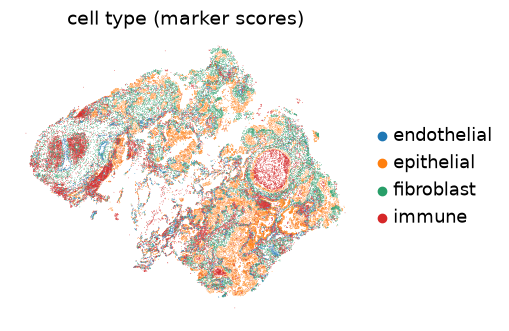

In [5]:
cnv.pl.spatial_cnv(adata, color="cell_type", size=1, title="cell type (marker scores)")

## Gene positions

The genomic positions of the genes come from the GENCODE v44 annotation, downloaded once with {mod}`pooch`. The
Xenium panel lists Ensembl gene ids, which we match to the GTF.

In [6]:
gtf = pooch.retrieve(
    "https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_44/gencode.v44.annotation.gtf.gz",
    known_hash="sha256:01f817afed65feee863361b4baf30a95e722ee5c5d508ff77b04106ef7ba20d3",
    fname="gencode.v44.annotation.gtf.gz",
    path=pooch.os_cache("infercnvpy"),
)
cnv.io.genomic_position_from_gtf(gtf, adata, gtf_gene_id="gene_id", adata_gene_id="gene_ids")
genes_per_chromosome = adata.var["chromosome"].value_counts()
genes_per_chromosome[genes_per_chromosome.index.str.fullmatch(r"chr[0-9]+")].agg(["min", "max"])

min     58
max    536
Name: count, dtype: int64

## Which arms can this panel see?

Before we infer CNVs, {func}`infercnvpy.tl.detectability` estimates how many cells a test needs to detect a gain of
one copy (1.5x) or the loss of one copy (0.5x) on each chromosome arm. It uses the raw counts, the depth and the
expression of each cell type, and it measures the noise on the reference cells. We give the cell types as `groupby`,
so that each type gets its own row. The heatmap shows the cells needed for a gain.

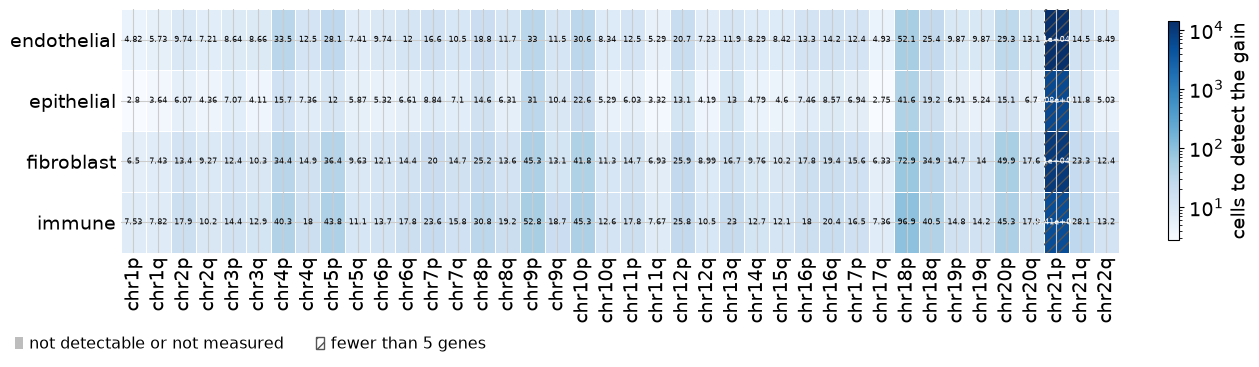

In [7]:
reference_types = ["immune", "endothelial", "fibroblast"]
cnv.tl.detectability(
    adata, layer="counts", groupby="cell_type", reference_key="cell_type", reference_cat=reference_types
)
cnv.pl.detectability(adata)

In [8]:
table = adata.uns["detectability"]["table"]
arms = table[table["group"] == "epithelial"].assign(arm=lambda t: t["arm"].astype(str)).set_index("arm")
blind = arms.index[(arms["n_genes"] < 5) | ~np.isfinite(arms["cells_gain"])]
print(f"arms with fewer than 5 genes or no information: {', '.join(blind)}")
columns = ["n_genes", "null_var", "cells_gain", "cells_gain_ideal", "cells_loss", "cells_loss_ideal"]
summary = arms.loc[["chr3p", "chr3q"], columns].astype(float)
summary.loc["median over arms"] = arms[columns].median()
summary.round(1)

arms with fewer than 5 genes or no information: chr21p


,n_genes,null_var,cells_gain,cells_gain_ideal,cells_loss,cells_loss_ideal
arm,,,,,,
chr3p,132.0,1.1,7.1,6.3,5.4,4.8
chr3q,144.0,1.2,4.1,3.5,3.1,2.7
median over arms,112.5,1.1,6.9,6.2,5.3,4.7


For the epithelial cells, the median arm needs 6.9 cells to detect a gain and 5.3 cells to detect a loss
(table above). A few arms need more, e.g. 9p (31 cells) and 18p (42 cells), and fibroblasts and immune cells
need about twice as many cells as epithelial cells on most arms (heatmap). The achievable columns (`cells_gain`, `cells_loss`) include the extra variance that normal cells show on
an arm (`null_var`), for example when a cell program moves the genes of an arm together. The ideal columns
(`_ideal`) count only the noise of counting, so they ask for fewer cells, by about the factor `null_var`. Here
`null_var` is only 1.1 for the median arm, so the two columns are close (6.9 and 6.2 cells for a gain). On panel cuts
of an Atera breast sample, an ideal test needed about as many cells as the achievable column, so the achievable column
is the one to plan with.

The table describes an ideal test that knows the normal expression of every cell type. {func}`infercnvpy.tl.infercnv`
estimates that expression from the data, and on the same panel cuts it needed about 2 to 6 times as many cells on a
5K panel (see the calibration table of {func}`infercnvpy.tl.detectability`). We smooth over 10 neighbors, so each
smoothed profile averages 11 cells, more than the 7 or so cells that an ideal test needs for a typical arm. For
`tl.infercnv` the same arm needs about 14 to 41 cells, so a single smoothed profile is still noisy, and the arm
changes show most clearly in averages over many cells, as in the heatmaps and maps below. More neighbors would
reduce the noise further, but they would also blur the borders between tumor and normal tissue.

Arms with fewer than 5 panel genes are hatched in the heatmap, and gray cells mark arms where no number of cells
detects the change. On this panel, only 21p has fewer than 5 genes, and the p arms of chromosomes 13, 14, 15 and 22
have no panel genes and no column. The panel can't resolve these arms, so a flat stretch on them in the CNV
heatmaps below means that we can't tell, and not that the copy number is normal.

## Planning a panel

The same function helps to choose a panel and a depth before an experiment. Pass the genes of the panel as a list
and an AnnData of raw counts from a similar tissue as `expression`, and set the expected median counts per cell
with `counts_per_cell`. Here we use this section as the expression and compare its full panel with a random subset
of 400 of its genes, at 100 and 300 counts per cell. The random subset is only a stand-in for a smaller panel, since
a real targeted panel picks its genes by cell type and not at random.

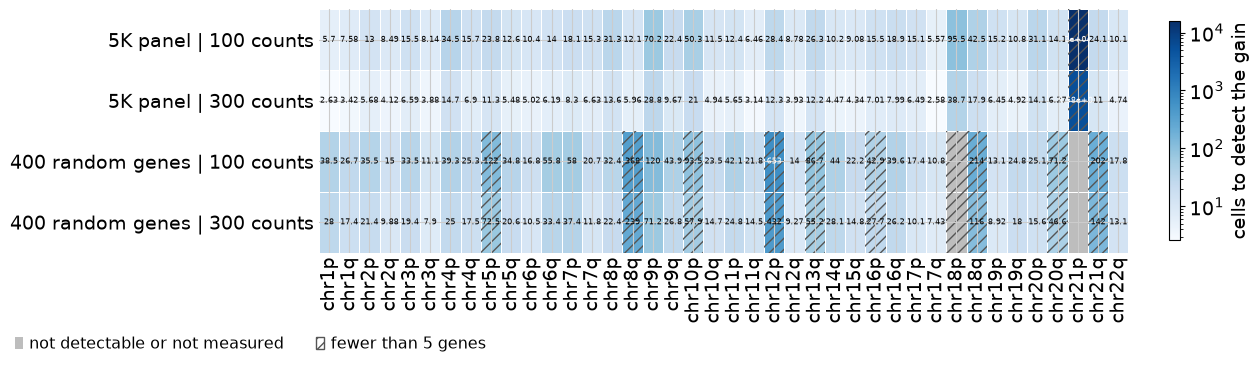

,5K panel,400 random genes
depth,,
100.0,15.166317,35.526942
300.0,6.466905,22.401486


In [9]:
rng = np.random.default_rng(0)
panels = {"5K panel": list(adata.var_names), "400 random genes": list(rng.choice(adata.var_names, 400, replace=False))}
plans = {
    name: cnv.tl.detectability(
        genes,
        expression=adata,
        layer="counts",
        groupby="cell_type",
        reference_key="cell_type",
        reference_cat=reference_types,
        counts_per_cell=[100, 300],
    )
    for name, genes in panels.items()
}
epithelial_plans = {name: plan[plan["group"] == "epithelial"] for name, plan in plans.items()}
cnv.pl.detectability(epithelial_plans)
pd.DataFrame({name: plan.groupby("depth")["cells_gain"].median() for name, plan in epithelial_plans.items()})

With the 5K panel, the median arm of the epithelial cells needs 15 cells at 100 counts per cell and 6.5 cells
at 300 counts. With the 400 random genes, it needs 36 and 22 cells, many arms have fewer than 5 genes (hatched), and 18p and
21p have no information at all (gray). At the same counts per cell, the smaller panel puts
more counts on each gene, and the extra variance of each gene's counts limits how much those extra counts help. To
decide on a panel and depth, run the function on the candidate
panels with expression from the planned tissue, and check that the arms you care about need fewer cells than you
expect per clone or per spatial neighborhood, with room for the factor that `tl.infercnv` needs on top. The 5K
panel at 300 counts and the 400 genes at both depths lie above the counts that these genes have in this section, so
`tl.detectability` scales the expected counts up instead of thinning them (`null_var_source="extrapolated"`), and these
rows are less certain than the 5K panel at 100 counts.

## Infer CNVs and smooth them over the tissue

{func}`infercnvpy.tl.infercnv` runs as for single-cell data. The panel has 58 to 536 genes per autosome (printed above),
so we use running windows of 51 genes, every 5 genes, instead of the defaults
(100 and 10). We turn off the noise filter (`dynamic_threshold=None`), because it sets small values to 0 and
{func}`infercnvpy.tl.smooth_cnv` would then average those zeros. Then we build a spatial graph of the 10 nearest
neighbors of each cell with squidpy and average each cell's CNV profile with its neighbors. By default, the cell
itself counts as one more neighbor.

In [10]:
cnv.tl.infercnv(
    adata,
    reference_key="cell_type",
    reference_cat=["immune", "endothelial", "fibroblast"],
    window_size=51,
    step=5,
    dynamic_threshold=None,
)
sq.gr.spatial_neighbors_knn(adata, n_neighs=10)
cnv.tl.smooth_cnv(adata)
adata.obsm["X_cnv"].shape, adata.obsm["X_cnv_smoothed"].shape

INFO     Creating graph using `None` transform and `1` libraries.                                                  


((56265, 744), (56265, 744))

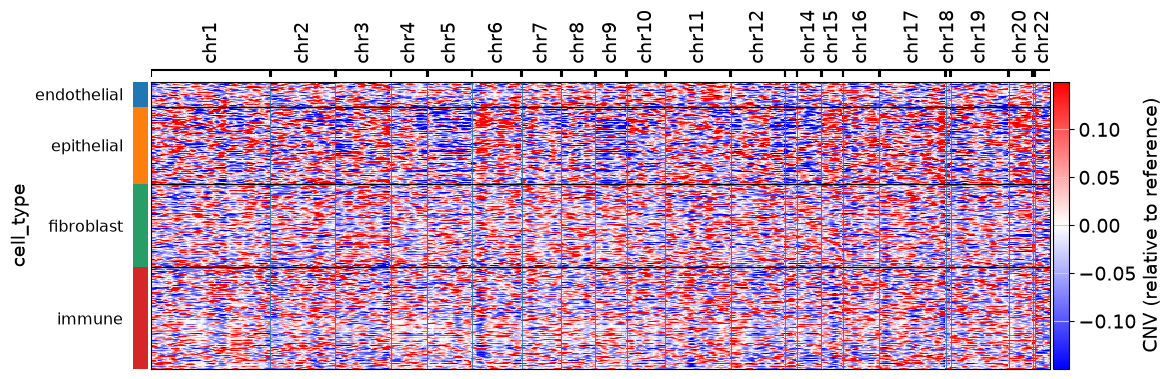

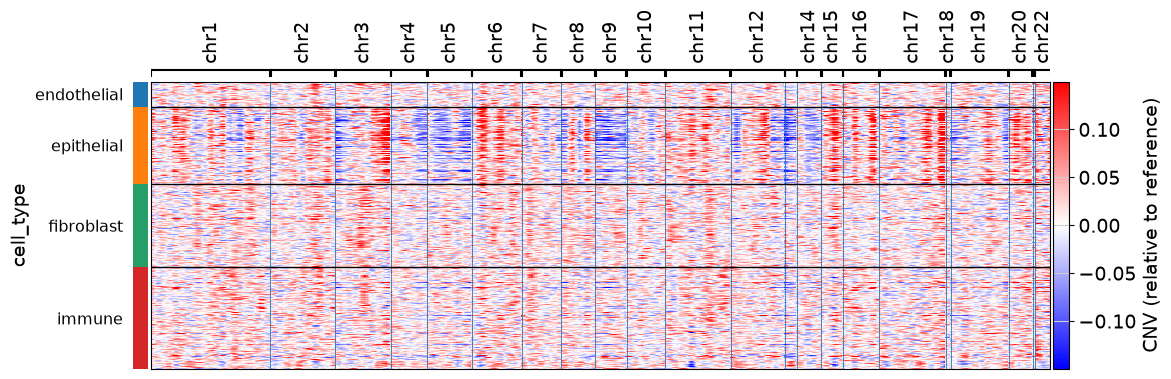

In [11]:
heatmap = {"groupby": "cell_type", "figsize": (12, 4), "vmin": -0.15, "vmax": 0.15}
cnv.pl.chromosome_heatmap(adata, **heatmap)
cnv.pl.chromosome_heatmap(adata, use_rep="cnv_smoothed", **heatmap)

Smoothing removes much of the noise of single cells, and the epithelial cells show a loss of 3p and a gain of 3q.
On the tissue, we plot the mean CNV of each arm of chromosome 3 (the windows whose midpoint lies in the arm, using the
window positions that `tl.infercnv` stores; the centromere is at about 91 Mb in GRCh38). The loss of 3p marks epithelial
regions of the section. The 3q map is red across most of the section, including regions of fibroblasts and immune
cells, so 3q is less specific here. The detectability table above predicted that both arms are easy to see on this panel, with 5.4 epithelial cells
for a loss of 3p and 4.1 cells for a gain of 3q.

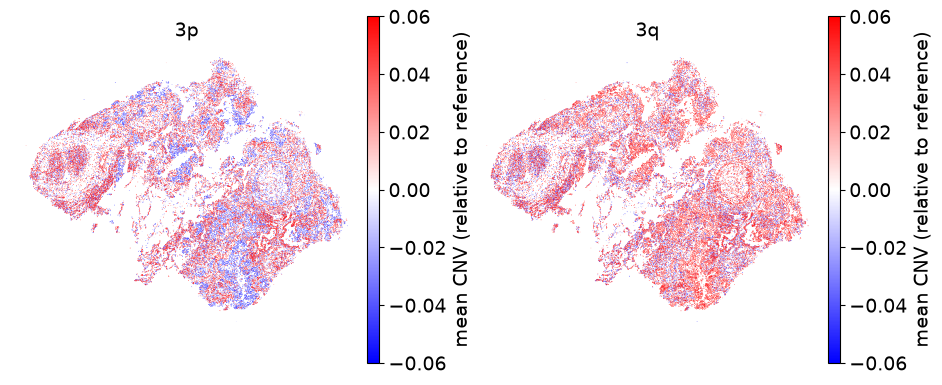

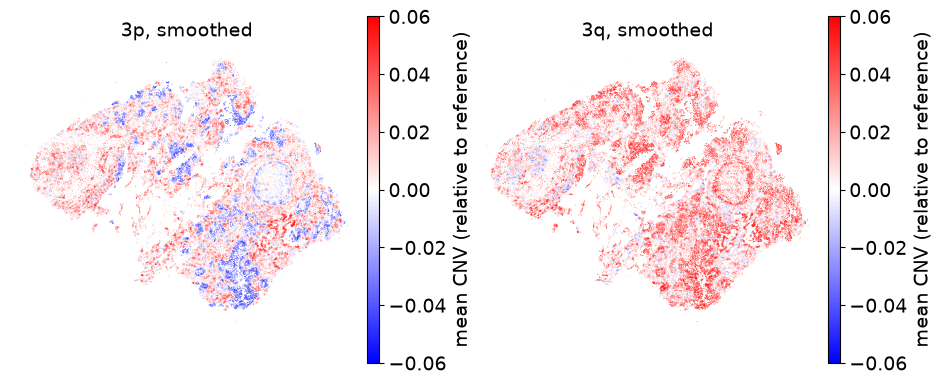

In [12]:
arms = ["chr3:0-90_000_000", "chr3:93_000_000-199_000_000"]
cnv.pl.spatial_cnv(adata, region=arms, size=1, vmin=-0.06, vmax=0.06, title=["3p", "3q"])
cnv.pl.spatial_cnv(
    adata, region=arms, use_rep="cnv_smoothed", size=1, vmin=-0.06, vmax=0.06, title=["3p, smoothed", "3q, smoothed"]
)

## Tumor calls

We score each cell by the mean absolute value of its smoothed CNV profile and call it tumor when the score is above
the 95th percentile of the scores of the reference cells, so the score and the threshold are both per cell. By
construction, 5% of the reference cells are called tumor, and normal cells of types outside the reference can exceed
the threshold as well.

In [13]:
reference = adata.obs["cell_type"].isin(["immune", "endothelial", "fibroblast"]).to_numpy()
cell_score = np.abs(adata.obsm["X_cnv_smoothed"]).mean(axis=1)
threshold = np.quantile(cell_score[reference], 0.95)
adata.obs["cnv_call"] = pd.Categorical(np.where(cell_score > threshold, "tumour", "normal"))
calls = pd.crosstab(adata.obs["cell_type"], adata.obs["cnv_call"])
print(f"threshold: {threshold:.4f}")
print(
    f"share of tumour calls that are not epithelial: {1 - calls.loc['epithelial', 'tumour'] / calls['tumour'].sum():.1%}"
)
calls

threshold: 0.0366
share of tumour calls that are not epithelial: 17.1%


cnv_call,normal,tumour
cell_type,,
endothelial,4810,143
epithelial,5063,10020
fibroblast,15714,713
immune,18598,1204


Most epithelial cells are called tumor. The fibroblasts, immune and endothelial cells among the tumor calls (share
printed above) are the 5% of reference cells above the threshold. The tumor calls show the loss of 3p, the gain of
3q and losses on chromosomes 4, 5 and 9.

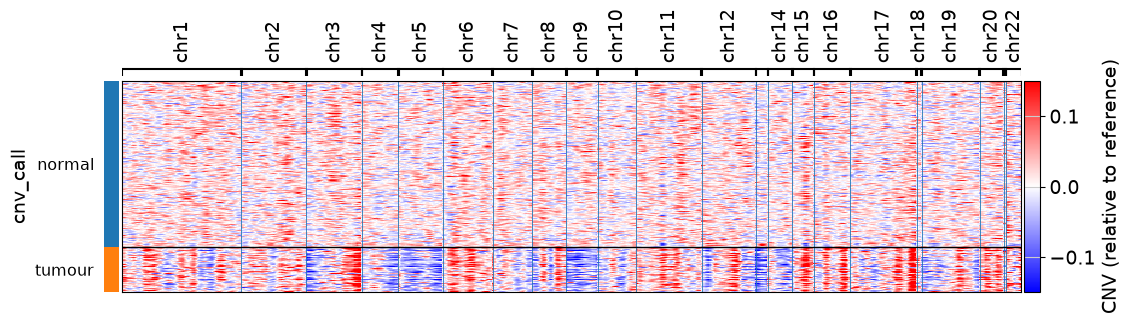

In [14]:
cnv.pl.chromosome_heatmap(adata, groupby="cnv_call", use_rep="cnv_smoothed", figsize=(12, 3), vmin=-0.15, vmax=0.15)

## Spatially coherent regions

{func}`infercnvpy.tl.spatial_regions` makes labels spatially coherent: a cell takes the label of its neighborhood
when enough neighbors disagree with it (for two labels and the default `beta=2`, more than 75% of them).
The calls from the smoothed profiles are already spatially coherent, and few cells change.

In [15]:
cnv.tl.spatial_regions(adata, key="cnv_call")
print(f"{(adata.obs['cnv_call'] != adata.obs['cnv_call_spatial']).sum()} of {adata.n_obs} cells changed their label")
pd.crosstab(adata.obs["cnv_call"], adata.obs["cnv_call_spatial"])

599 of 56265 cells changed their label


cnv_call_spatial,normal,tumour
cnv_call,,
normal,44017,168
tumour,431,11649


The prior matters more for noisy labels. Calls of single cells from the unsmoothed CNV profiles, with the same rule,
are scattered over the section (left in the figure below). With `beta=4` (a cell changes its label when more than
62.5% of its neighbors disagree), `tl.spatial_regions` removes about half of the tumor calls (8,978 to 4,842 in the
table below), including 87% of the calls of non-epithelial cells (middle). It doesn't recover tumor cells that the
unsmoothed profiles miss, so the regularized calls from the smoothed profiles (right) include more than twice as many
epithelial cells.

In [16]:
raw_score = np.asarray(abs(adata.obsm["X_cnv"]).mean(axis=1)).ravel()
raw_threshold = np.quantile(raw_score[reference], 0.95)
adata.obs["cnv_call_raw"] = pd.Categorical(np.where(raw_score > raw_threshold, "tumour", "normal"))
cnv.tl.spatial_regions(adata, key="cnv_call_raw", beta=4)
epithelial = np.where(adata.obs["cell_type"] == "epithelial", "epithelial", "other")
keys = ["cnv_call_raw", "cnv_call_raw_spatial", "cnv_call_spatial"]
pd.DataFrame({key: (adata.obs[key] == "tumour").groupby(epithelial).sum() for key in keys}).T.rename_axis(
    "tumour calls"
)

,epithelial,other
tumour calls,,
cnv_call_raw,6918,2060
cnv_call_raw_spatial,4580,262
cnv_call_spatial,9984,1833


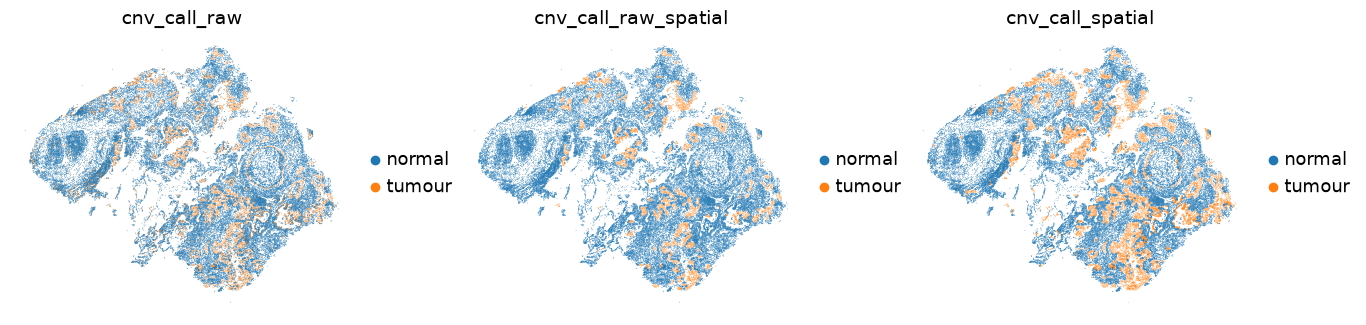

In [17]:
cnv.pl.spatial_cnv(adata, color=["cnv_call_raw", "cnv_call_raw_spatial", "cnv_call_spatial"], size=1)

## Clones with tl.copy_number

{func}`infercnvpy.tl.copy_number` calls copy number from the raw counts with a count model. It returns aneuploid and
diploid labels, clones and segments (see {doc}`the API overview <../api>`). We give it the same reference cells
and smooth its results over the spatial graph from above, with `connectivity_key`. Xenium cells have fewer detected
genes than droplet cells, so we lower `min_genes` from 200 to 100, and cells below it are labelled "not.defined".
The panel passes the check of `tl.copy_number` for small panels (at least 1,000 usable genes and a median of 150
counts per cell), so it calls the cells instead of labelling them "undetermined".

In [18]:
cnv.tl.copy_number(
    adata,
    layer="counts",
    reference_key="cell_type",
    reference_cat=reference_types,
    min_genes=100,
    connectivity_key="spatial_connectivities",
)
print(adata.obs["copy_number"].value_counts())
adata.uns["copy_number"]["clones"]

copy_number
diploid         39603
not.defined      9022
aneuploid        7640
undetermined        0
Name: count, dtype: int64


,n_cells,aneuploid,amplitude,burden
N0,39603,False,0.009202,0.000000
T1,7640,True,0.168963,0.531502


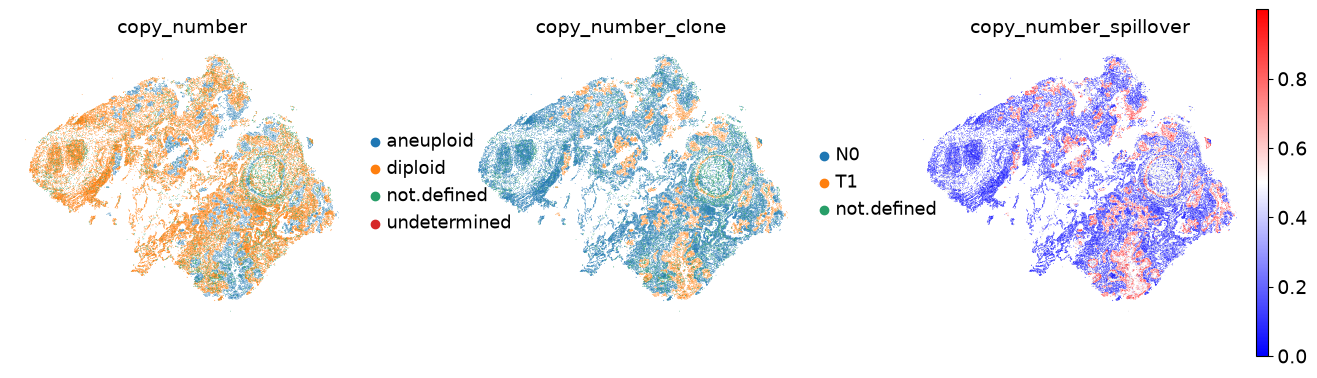

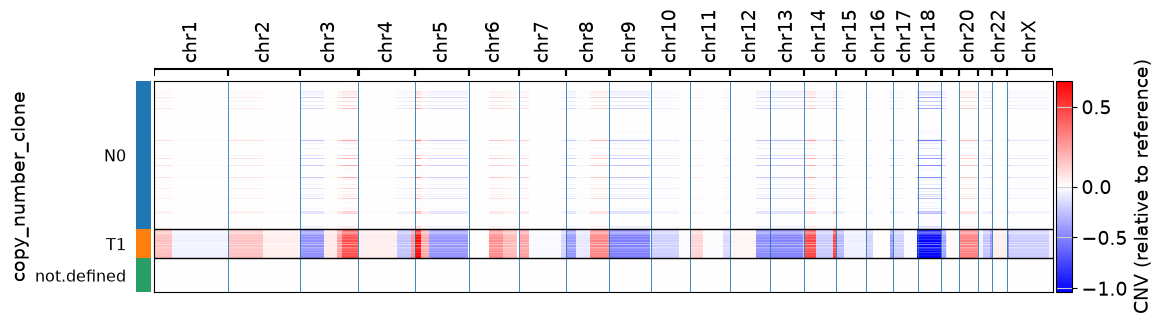

In [19]:
cnv.pl.spatial_cnv(adata, color=["copy_number", "copy_number_clone", "copy_number_spillover"], size=1)
cnv.pl.chromosome_heatmap(adata, groupby="copy_number_clone", use_rep="copy_number", figsize=(12, 3))

`tl.copy_number` finds one aneuploid clone, T1, with 7,640 cells, and labels 39,603 cells diploid (clone N0).
The 9,022 cells with fewer than 100 detected genes are "not.defined". In the clone heatmap, T1 shows the loss of 3p and the gain of 3q, together with
gains of 5p and 8q and losses of 5q, 9, 13 and 18. The spillover score is the share of a cell's
counts that the pooled expression of the aneuploid cells explains best. High values in normal cell types point to
segmentation merges with tumor cells. The table below compares the labels with the threshold calls from above, per
cell type.

In [20]:
cell_type = adata.obs["cell_type"]
pd.DataFrame(
    {
        "threshold tumour calls": (adata.obs["cnv_call_spatial"] == "tumour").groupby(cell_type, observed=True).mean(),
        "copy_number aneuploid": (adata.obs["copy_number"] == "aneuploid").groupby(cell_type, observed=True).mean(),
        "median spillover": adata.obs["copy_number_spillover"].groupby(cell_type, observed=True).median(),
    }
).round(3)

,threshold tumour calls,copy_number aneuploid,median spillover
cell_type,,,
endothelial,0.021,0.002,0.002
epithelial,0.662,0.474,0.512
fibroblast,0.040,0.007,0.000
immune,0.054,0.019,0.010


`tl.copy_number` labels fewer cells aneuploid than the threshold calls. It labels 47% of the epithelial cells
aneuploid, against 66% tumor calls by the threshold, and 0.2% to 1.9% of the reference cell types, against 2.1% to
5.4% by the threshold. The shares count the "not.defined" cells as not aneuploid. The threshold rule calls 5% of the
reference cells tumor by construction, while `tl.copy_number` has no such fixed rate. The median spillover is 0.01 or
less in the reference cell types, so few of them look like merges with tumor cells.

## Notes

- With 10 neighbors and the default weight of the cell itself, a cell's own profile is 1/11 of its smoothed profile, so calls from
  smoothed profiles are calls of neighborhoods. Smoothing mixes the profiles of tumor and normal cells at the
  tumor boundary and of immune cells that infiltrate the tumor, over about `n_hops` cells. Use the unsmoothed
  `X_cnv` for per-cell questions in mixed regions.
- The spatial graph defines the neighborhood. A kNN graph adapts to the cell density; a radius graph
  ({func}`squidpy.gr.spatial_neighbors_radius`) keeps the physical scale fixed. `n_hops=2` in `tl.smooth_cnv`
  widens the neighborhood further.
- `tl.spatial_regions` changes labels only as long as a single change makes them more coherent, so the result stays
  close to the input labels and is not a new clustering. Larger `beta` gives smoother regions.